# Protocole de comparaison des librairies d'analyse des trajectoires : `Sequenzo`
Garance Malnoë - Avril 2026

# 1. Introduction

L'objectif de ce document est de proposer une vue d'ensemble des possibilités qu'offre la librairie ``Sequenzo`` en Python pour l'analyse de séquences, et plus généralement de trajectoires. Ce document a été pensé pour être mis en parallèle avec son équivalent dédié aux packages ``TraMineR`` (+`TraMineRextras`) en R et `TanaT` en Python également, afin de comparer les trois outils et de déterminer le plus adapté selon la situation à traiter.

Pour faciliter cette comparaison, les trois documents suivent le même plan :

- Présentation des formats de données acceptés par les packages.
- Exploration des jeux de données intégrés et méthodes de simulation.
- Introduction des données "fil rouge" utilisées pour illustrer la suite du document.
- Manipulation des données et sélection des séquences selon différents critères.
- Description statistique et visualisation des séquences.
- Construction de typologies (calcul des dissimilarités et algorithmes de clustering), incluant le cas multidimensionnel (*multichannel*).
- Autres analyses (divergence, survie, test entre groupes, formatage pour autres analyses)
- Autres possibilités (séquences d'événements et séquences d'intervalles).

Nous traiterons dans ce document essentiellement de l'analyse de séquences d'**états**. Les autres types (événements et intervalles) seront spécifiquement abordés dans la dernière section.

In [1]:
import sequenzo
import time
import pandas as pd
import numpy as np
import random
from datetime import datetime
import datetime as dt
from scipy.stats import entropy
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from functools import reduce


# 2. Format de données

Le seul format de données accepté par `Sequenzo` est le format STS avec une ligne par individu et une colonne par point dans le temps.

Prenons l'exemple avec deux séquences $X$ et $Y$, où $a$, $b$ et $c$ représentent les états possibles (l'alphabet):
$$
X = (a,a,a,b,b,c,c) \quad\text{et}\quad Y = (a,a,a,c,c,c,c)
$$

In [2]:
df_exemple = pd.DataFrame(
    {
        "id":["X","Y"],
        "t1":["a","a"],
        "t2":["a","a"],
        "t3":["a","a"],
        "t4":["b","c"],
        "t5":["b","c"],
        "t6":["c","c"],
        "t7":["c","c"]
    }
)
df_exemple

,id,t1,t2,t3,t4,t5,t6,t7
0,X,a,a,a,b,b,c,c
1,Y,a,a,a,c,c,c,c


Ainsi, la librairie est assez restrictive vis-à-vis du format accepté pour la création d'un objet sequence. Cependant, elle met à disposition deux fonctions permettant de convertir les données du format STS au format SPELL et inversement.

In [3]:
df_long = sequenzo.wide_to_long_format_data(
    df_exemple,
    id_col="id",
    time_cols=["t1","t2","t3","t4","t5","t6","t7"],
    var_name="time_point",
    value_name="state"
)
df_long.sort_values("id")

,id,time_point,state
0,X,t1,a
2,X,t2,a
4,X,t3,a
6,X,t4,b
8,X,t5,b
10,X,t6,c
12,X,t7,c
1,Y,t1,a
3,Y,t2,a
5,Y,t3,a


In [4]:
df_wide = sequenzo.long_to_wide_format_data(
    df_long,
    id_col="id",
    time_col="time_point",
    value_col="state"
)
df_wide

,id,state_t1,state_t2,state_t3,state_t4,state_t5,state_t6,state_t7
0,X,a,a,a,b,b,c,c
1,Y,a,a,a,c,c,c,c


Pour les autres formats de données, il sera nécessaire à l'utilisateur de procéder lui-même à une conversion à partir de librairies de transformation de données comme `pandas`.

Définition d'une séquence à partir des données au format STS :

In [5]:
sequence = sequenzo.SequenceData(
    data=df_exemple,
    time=["t1","t2","t3","t4","t5","t6","t7"],
    states=['a','b','c'],
    labels=['a','b','c'],
    id_col='id'
)


[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 2
[>] Number of time points: 7
[>] Min/Max sequence length: 7 / 7
[>] States: ['a', 'b', 'c']
[>] Labels: ['a', 'b', 'c']
[>] Weights: Not provided


# 3. Données exemples et simulations

### Jeux de données exemple

La librairie `Sequenzo` met à disposition plusieurs jeux de données pour illustrer ses fonctionnalités :
| Jeu de données | Type de séquence | Thématique | Individus | Longueur | États | Covariables |
|:---|:------|:------|--:|-----:|------:|--:|
| **`biofam`**  + version binaire pour les états (left, married et child) | Etats | Statut familial (Swiss Household Panel) | 2000 | 16 | 8 | 7 | 
| **`Chinese Territories' Colonial History`** | Etats |  Statut de souveraineté de territoires chinois   | 11 | 111 | 7 | 0 |
| **`Country child mortality`** | Etats | Mortalité infantile dans les pays du monde | 194 | 302 | 10 | 0 |
| **`Country GPD per capita`** | Etats | Emissions de CO2  | 193 | 223 | 5 | 0 |
| **`CO₂ Emissions Dataset`** (découpage en déciles ou quintiles / découpage local ou global) | Etats | Emissions de CO2  | 193 | 223 | 5 ou 10 | 0 |
| **`Country life expectancy`** | Etats | Espérance de vie dans les pays du monde | 194 | 302 | 10 | 0 |
| **`dyadic`** (children) | Etats | Formation de la famille de 15 à 39 ans, enfants | 60 | 24 | 6 | 1 |
| **`dyadic`** (parents) | Etats |  Formation de la famille de 15 à 39 ans, parents | 60 | 24 | 6 | 1 |
| **`mvad`** | Etats | Transition école-travail | 712 | 72 | 6 | 13 |
| **`pairfam activity`** (par mois) | Etats | Trajectoires d'emploi / d'activité | 1027 | 264 | 8 | 16 |
| **`pairfam activity`** (par années) | Etats | Trajectoires d'emploi / d'activité | 1027 | 22 | 8 | 0 |
| **`pairfam family`** (par mois) | Etats | Formation de la famille| 1027 | 264 | 9 | 16 |
| **`pairfam family`** (par années) | Etats | Formation de la famille | 1027 | 22 | 9 | 0 |
| **`political science aid shock`** | Etats | Sciences politiques | 165 | 36 | 2 | 0 |
| **`political science donor fragmentation`** | Etats | Sciences politiques | 156 | 36 | 3 | 0 |
| **`College Students' stress`** | Etats | Evolution du stress d'étudiants | 76 | 8 | 3 | 5 |

`Sequenzo` propose plusieurs jeux de données multichannel : `dyadic`, `pairfam` et `political science`, à chaque fois avec deux domaines.

### Simulations de données

La librairie n'offre pas la possibilité de simuler des données. Toutefois, il est possible pour l'utilisateur de le faire par lui-même en utilisant des librairies telles que `random` et `numpy`.

In [6]:
import numpy as np
import pandas as pd

def seqgen(
    n: int,
    length,  # int ou array-like de longueur n
    alphabet: list,
    p: list = None,
    id_prefix: str = "seq",
    missing: str = None,
    p_missing: float = 0.0,
    pad: str = "NA",
    seed: int = None
) -> pd.DataFrame:
    """
    Génère n séquences aléatoires au format STS (State Sequence).

    Paramètres
    ----------
    n : int
        Nombre de séquences à générer.
    length : int ou array-like de longueur n
        Longueur de chaque séquence. Si un entier est fourni, toutes les
        séquences ont la même longueur. Si un vecteur est fourni, chaque
        séquence i a la longueur length[i].
    alphabet : list
        Liste des états possibles.
    p : list, optional
        Probabilités associées à chaque état (doit sommer à 1).
        Si None, distribution uniforme.
    id_prefix : str, optional
        Préfixe pour les identifiants de séquences (défaut : "seq").
    missing : str, optional
        Valeur représentant les données manquantes (ex : "*" comme dans TraMineR).
        Si None, pas de données manquantes générées.
    p_missing : float, optional
        Probabilité qu'un état soit manquant (entre 0 et 1). Ignoré si missing=None.
    pad : str, optional
        Valeur utilisée pour remplir les positions inexistantes des séquences
        plus courtes que la longueur maximale (défaut : "NA").
    seed : int, optional
        Graine pour la reproductibilité.

    Retourne
    --------
    pd.DataFrame
        DataFrame au format STS : colonne 'id' + colonnes 't1' à 't{max_length*'.
        Les positions hors longueur individuelle sont remplies avec `pad`.
    """
    rng = np.random.default_rng(seed)

    # Normalisation de length en vecteur
    if np.isscalar(length):
        lengths = np.full(n, length, dtype=int)
    else:
        lengths = np.asarray(length, dtype=int)
        if len(lengths) != n:
            raise ValueError("'length' doit être un scalaire ou un vecteur de longueur n.")
        if np.any(lengths <= 0):
            raise ValueError("Toutes les valeurs de 'length' doivent être strictement positives.")

    max_length = lengths.max()

    # Validation des probabilités
    if p is not None:
        p = np.array(p, dtype=float)
        if len(p) != len(alphabet):
            raise ValueError("'p' doit avoir la même longueur que 'alphabet'.")
        if not np.isclose(p.sum(), 1.0):
            raise ValueError("Les probabilités dans 'p' doivent sommer à 1.")
    else:
        p = np.ones(len(alphabet)) / len(alphabet)

    if not (0.0 <= p_missing < 1.0):
        raise ValueError("'p_missing' doit être compris entre 0 (inclus) et 1 (exclus).")

    # Génération séquence par séquence (longueurs variables)
    sequences = []
    for i in range(n):
        seq = rng.choice(alphabet, size=lengths[i], p=p).astype(object)

        # Injection de valeurs manquantes
        if missing is not None and p_missing > 0.0:
            mask = rng.random(size=lengths[i]) < p_missing
            seq[mask] = missing

        # Padding jusqu'à max_length
        padding = np.full(max_length - lengths[i], pad, dtype=object)
        sequences.append(np.concatenate([seq, padding]))

    # Construction du DataFrame STS
    ids = [f"{id_prefix}_{i+1}" for i in range(n)]
    col_names = [f"t{j+1}" for j in range(max_length)]
    df = pd.DataFrame(sequences, columns=col_names)
    df.insert(0, "id", ids)

    return df

In [7]:
# Exemple de 10 séquences de longueur 12 avec pour alphabet {a, b, c} avec une répartition p=[0.75,0.1,0.15] et 10% de données manquantes
seqgen(n=3, length=[8,10,7], alphabet=["a","b","c"],p=[0.75,0.1,0.15],missing="Missing",p_missing=0.1)

,id,t1,t2,t3,t4,t5,t6,t7,t8,t9,t10
0,seq_1,b,a,a,a,a,a,a,a,NA,NA
1,seq_2,a,b,a,c,a,c,a,a,a,a
2,seq_3,c,b,a,a,a,c,Missing,NA,NA,NA


# 4. Données fil-rouge

Pour réaliser cette comparaison systématique, nous utilisons les mêmes jeux de données dans les trois environnements. Pour cela, nous nous appuyons sur le Swiss Household Panel (SHP), une étude longitudinale d'envergure nationale lancée en 1999 qui recueille annuellement des informations sociodémographiques et économiques auprès d'un échantillon représentatif de ménages suisses. Pour les analyses de séquences unidimensionnelles, nous nous appuyons sur le jeu de données _*Family life states* `biofam`, notamment proposé comme jeu de données exemple par `TraMineR` et `sequenzo`. Pour les analyses nécessitant des séquences multidimensionnelles avec plusieurs thématiques, nous travaillons à partir d'un extrait plus large du Swiss Household Panel `extract_shp` que nous avons réalisé nous-mêmes. Nous décrivons plus en détail ces deux jeux-de données ci-après.

### *Family life states* `biofam`
Le jeu de données *Family life states* (`biofam`) est issu de l'enquête biographique rétrospective menée en 2002 dans le cadre du panel suisse de ménages. Il documente les trajectoires de formation familiale d'un échantillon de 2 000 individus sur une période de seize années, sans données manquantes, retraçant l'évolution de leur situation familiale de l'âge de 15 ans à l'âge de 30 ans.

Ces séquences sont initialement structurées au format **STS** et donc sont directement exploitables par `TraMineR`. Une version convertie au format **SPELL** est utilisée pour `TanaT`. L'alphabet des séquences décrites dans ce jeu de données est composé de huit statuts familiaux décrivant à la fois le lieu de résidence, le statut marital et la parentalité. Les individus sont ainsi catégorisés à chaque pas de temps selon qu'ils vivent au domicile parental (*Parent*), qu'ils l'ont quitté (*Left*), qu'ils ont un enfant (*Child*), qu'ils sont mariés (*Married*) qu'ils ont quitté le domicile familial et qu'ils sont mariés (*Left+Marr*), qu'ils ont quitté le domicile familial et ont un enfant (*Left+Child*), qu'ils soient hors du domicile familial, mariés et avec un enfant (*Left+Marr+Child*) ou qu'ils soient divorcés (*Divorced*).

En complément de la séquence d'états, le jeu de données inclut plusieurs covariables transversales: caractéristiques socio-démographiques de l'individu (sexe, année de naissance, première nationalité, langue de réponse au questionnaire) et culturelles (religion et participation religieuse), ainsi que sur l'origine sociale avec le statut social du père et de la mère. Cependant, certaines de ces variables sont manquantes chez certains individus. Nous utilisons uniquement la variable sexe (disponible pour l'ensemble des individus) dans nos comparaisons.

Enfin, ce jeu de données propose deux sets de poids : l'un ajusté sur l'ensemble de la population suisse et l'autre ramené à la taille de l'échantillon. Cependant, ils ne sont fournis qu'à titre illustratif, puisque ce jeu de données est un sous-échantillon des réponses globales du panel et donc les poids proposés ne sont plus adaptés.

### Extrait du Swiss Household Panel `extract_shp`
Le jeu de données `extract_shp` est un extrait des réponses à l'enquête longitudinale menée auprès d'un panel de ménages suisses entre 1999 et 2018 inclus. Nous avons sélectionné uniquement les ménages sans données manquantes et ayant participé à l'enquête chaque année, ce qui conduit à 20 observations pour 1032 foyers. Six variables ont été retenues afin de constituer trois thématiques, comprenant chacune une à trois variables évoluant au fil du temps :

**Thématique familiale :**
Pour cette thématique, nous considérons uniquement le nombre de personnes composant le ménage. Cette variable prend des valeurs allant de 1 à 12, que nous regroupons en cinq catégories : 1, 2, 3, 4, et 5 habitants ou plus au sein du foyer.

**Thématique résidentielle :**
Pour cette thématique, nous nous intéressons à la région d'habitation, au type de commune d'habitation et au statut résidentiel. La région d'habitation comporte sept modalités, les cantons correspondants étant précisés entre parenthèses : Lac Léman (VD, VS, GE), Middleland (BE, FR, SO, NE, JU), Suisse Nord-Ouest (BS, BL, AG), Zurich, Suisse Est (GL, SH, AR, AI, SG, GR, TG), Suisse Centrale (LU, UR, SZ, OW, NW, ZG) et Tessin.

La variable décrivant le type de commune d'habitation comporte neuf modalités : centres, communes de banlieue, communes aisées, communes urbaines périphériques, communes touristiques, communes industrielles et tertiaires, communes rurales de banlieue, communes mixtes agricoles et communes agricoles périphériques.

Enfin, le statut résidentiel comporte trois modalités : locataire, propriétaire ou copropriétaire, et locataire non payant.

**Thématique qualité de vie :**
Cette thématique est composée d'une variable décrivant l'état du lieu de vie du foyer et d'une variable mesurant la satisfaction à l'égard de la situation financière du foyer. L'état du lieu de vie comporte trois modalités : en mauvais état, en bon état mais n'ayant pas été rénové récemment, et neuf ou récemment rénové.

La satisfaction à l'égard de la situation financière du foyer prend des valeurs entières allant de 0 (pas du tout satisfait) à 10 (totalement satisfait). Nous regroupons cette variable en cinq catégories : 0-2, 3-4, 5-6, 7-8 et 9-10.

Cette base de données est proposée au format **SPELL**, compatible avec `TraMineR` et `TanaT`. Une version au format **STS** est utilisée pour `sequenzo`.

Dans le cadre de ce document, nous avons choisi de sélectionner ces variables et de regrouper certaines modalités afin de disposer d'un support permettant d'illustrer les possibilités des trois packages étudiés. Ce document n'a pas pour objectif de produire une véritable analyse et, dans un contexte applicatif réel, ces choix ne conduiraient pas nécessairement à des analyses pertinentes.

In [8]:
# Préparation du dataset biofam
biofam = pd.read_csv("../biofam.csv").dropna(axis=0,subset="id")
biofam_static = pd.read_csv("../biofam_sts.csv")

# Préparation du dataset extract_shp
extract_shp_long = pd.read_csv("../data_SHP.csv")
extract_shp_sts_region = sequenzo.long_to_wide_format_data(
    extract_shp_long,
    id_col="idhous",
    time_col="year",
    value_col="region"
)
extract_shp_sts_community = sequenzo.long_to_wide_format_data(
    extract_shp_long,
    id_col="idhous",
    time_col="year",
    value_col="com2_"
)
extract_shp_sts_type_logement = sequenzo.long_to_wide_format_data(
    extract_shp_long,
    id_col="idhous",
    time_col="year",
    value_col="hh29"
)
extract_shp_sts_nbpers = sequenzo.long_to_wide_format_data(
    extract_shp_long,
    id_col="idhous",
    time_col="year",
    value_col="nbpers"
)
extract_shp_sts_condlieuvie = sequenzo.long_to_wide_format_data(
    extract_shp_long,
    id_col="idhous",
    time_col="year",
    value_col="hh14"
)
extract_shp_sts_situatuionfinance = sequenzo.long_to_wide_format_data(
    extract_shp_long,
    id_col="idhous",
    time_col="year",
    value_col="hi30"
)
dfs = [
    extract_shp_sts_region, 
    extract_shp_sts_community, 
    extract_shp_sts_type_logement, 
    extract_shp_sts_nbpers, 
    extract_shp_sts_condlieuvie, 
    extract_shp_sts_situatuionfinance
]
extract_shp_sts = reduce(lambda left, right: pd.merge(left, right, on='idhous', how='left'), dfs)
extract_shp_sts.to_csv("C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts.csv")
sequenzo.clean_time_columns_auto(extract_shp_sts_region, prefix_patterns=["region_"]).to_csv("C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_region.csv")
sequenzo.clean_time_columns_auto(extract_shp_sts_community, prefix_patterns=["com2__"]).to_csv("C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_community.csv")
sequenzo.clean_time_columns_auto(extract_shp_sts_type_logement, prefix_patterns=["hh29_"]).to_csv("C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_type_logement.csv")
sequenzo.clean_time_columns_auto(extract_shp_sts_nbpers, prefix_patterns=["nbpers_"]).to_csv("C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_nbpers.csv")
sequenzo.clean_time_columns_auto(extract_shp_sts_condlieuvie, prefix_patterns=["hh14_"]).to_csv("C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_condlieuvie.csv")
sequenzo.clean_time_columns_auto(extract_shp_sts_situatuionfinance, prefix_patterns=["hi30_"]).to_csv("C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_situatuionfinance.csv")

# 5. Gestion de données

Pour l'analyse de séquence il peut se réveler très utile de filtrer et sélectionner des séquences sur certains critères comme la sélection d'un échantillon ou le respect d'une contrainte de temporelle. La librairie Python `TanaT` sépare le filtrage et la sélection des données en plusieurs catégories :

- **Query** : sélection par requête sur les états (ex. : présence de l'état A).
- **Static** : filtrage via les covariables des individus (ex. : sélection par genre).
- **Time** : restriction temporelle ou sélection sur une fenêtre de temps donnée (ex. : trajectoires entre 2001 et 2005).
- **Pattern** : recherche de motifs séquentiels précis (ex. : état A → état B → état D).
- **Length** : filtrage selon la longueur des séquences (ex. : taille strictement supérieure à 5).

Nous allons illuster ces différents filtrages par des exemples sur le jeu de données `biofam`.

Nous commençons par définir l'objet séquence avec `SequenceData`.

In [9]:
biofam = sequenzo.load_dataset("biofam")
biofam = biofam.reset_index()
biofam.head(5)

,index,idhous,sex,birthyr,nat_1_02,plingu02,p02r01,p02r04,cspfaj,cspmoj,...,23,24,25,26,27,28,29,30,wp00tbgp,wp00tbgs
0,0,66891.0,man,1943,Switzerland,german,Protestant or Reformed Church,religious celebrations and family events,other self-employed,other self-employed,...,0,3,6,6,6,6,6,6,1053.368652,0.934848
1,1,28621.0,man,1935,Switzerland,german,Roman Catholic,once a week,other self-employed,NaN,...,1,1,1,3,6,6,6,6,855.433899,0.759184
2,2,57711.0,woman,1946,Switzerland,french,no denomination or religion,only for family ceremonies,other self-employed,intermediate professions,...,1,1,1,1,3,6,6,6,575.205200,0.510486
3,3,17501.0,man,1918,Switzerland,german,Roman Catholic,once a week,top management,NaN,...,1,1,1,1,1,1,1,1,1527.391968,1.355536
4,4,147701.0,man,1946,Switzerland,german,Roman Catholic,only for family ceremonies,NaN,NaN,...,1,1,1,1,1,6,6,6,796.182678,0.706600


In [10]:
timepoints_columns = ["15","16","17","18","19","20","21","22","23","24","25","26","27","28","29","30"]
states_biofam =[0,1,2,3,4,5,6,7]
labels_biofam =['Parent','Left','Married','Left+Marr','Child','Left+Child','Left+Marr+Child','Divorced']
color_list=["#40b15c","#a89cec","#ffbb62","#f5ec73","#3760e9","#ee4091","#916237","#363631"]
biofam_seq = sequenzo.SequenceData(
    data=biofam,
    time= timepoints_columns,
    states=states_biofam,
    labels=labels_biofam,
    id_col='index',
    custom_colors=color_list
)


[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 2000
[>] Number of time points: 16
[>] Min/Max sequence length: 16 / 16
[>] States: [0, 1, 2, 3, 4, 5, 6, 7]
[>] Labels: ['Parent', 'Left', 'Married', 'Left+Marr', 'Child', 'Left+Child', 'Left+Marr+Child', 'Divorced']
[>] Weights: Not provided


### Query
**Exemple :** ne sélectionner que les séquences passant au moins une fois par l’état 1 (Left) au cours du temps.

In [11]:
# Récupération de l'index des individus ayant au moins l'état 1 (Left) dans leur séquence.
index_left = (biofam == 1).any(axis=1)
seq_left = biofam[index_left]

# Récréation d'un objet séquence à partir du df filtré
seq_filtered = sequenzo.SequenceData(
    data=seq_left,
    time=timepoints_columns,
    id_col="index",
    states=states_biofam,
    labels=labels_biofam
)

[i] Note: Some provided states are not observed in this dataset: [2, 4]
    Provided states are allowed to be a superset of observed values.
    Unique values actually in data: [0, 1, 3, 5, 6, 7]

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 896
[>] Number of time points: 16
[>] Min/Max sequence length: 16 / 16
[>] States: [0, 1, 2, 3, 4, 5, 6, 7]
[>] Labels: ['Parent', 'Left', 'Married', 'Left+Marr', 'Child', 'Left+Child', 'Left+Marr+Child', 'Divorced']
[>] Weights: Not provided


### Static
**Exemple :** sélection des personnes nées strictement après 1950.

In [12]:
# Récupération de l'index des individus ayant au moins l'état 1 (Left) dans leur séquence.
index_left = biofam["birthyr"] >1950
seq_left = biofam[index_left]

# Récréation d'un objet séquence à partir du df filtré
seq_filtered = sequenzo.SequenceData(
    data=seq_left,
    time=timepoints_columns,
    id_col="index",
    states=states_biofam,
    labels=labels_biofam
)


[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 569
[>] Number of time points: 16
[>] Min/Max sequence length: 16 / 16
[>] States: [0, 1, 2, 3, 4, 5, 6, 7]
[>] Labels: ['Parent', 'Left', 'Married', 'Left+Marr', 'Child', 'Left+Child', 'Left+Marr+Child', 'Divorced']
[>] Weights: Not provided


### Time
**Exemple :** sélectionner les séquences comprises (en entiereté) entre le temps 1 et le temps 8.

In [13]:
# Récupération de l'index des individus ayant une longueur inférieure ou égale à 8
sequences = biofam_seq.sequences
index_left = [len(sequences[i])<=8 for i in range(0,len(sequences))]
seq_left = biofam[index_left]

# Récréation d'un objet séquence à partir du df filtré
seq_filtered = sequenzo.SequenceData(
    data=seq_left,
    time=timepoints_columns,
    id_col="index",
    states=states_biofam,
    labels=labels_biofam
)

[i] Note: Some provided states are not observed in this dataset: [0, 1, 2, 3, 4, 5, 6, 7]
    Provided states are allowed to be a superset of observed values.
    Unique values actually in data: []

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 0
[>] Number of time points: 16
[>] Min/Max sequence length: nan / nan
[>] States: [0, 1, 2, 3, 4, 5, 6, 7]
[>] Labels: ['Parent', 'Left', 'Married', 'Left+Marr', 'Child', 'Left+Child', 'Left+Marr+Child', 'Divorced']
[>] Weights: Not provided


### Pattern
**Exemple :** présence du pattern Parent -> Left + Married.

In [14]:
# Construction de biofam avec uniquement les indices des personnes avec la transition 0 -> 3 (Parent->Left+Married)
arr = biofam[timepoints_columns].values
from_state = arr[:, :-1]
to_state   = arr[:, 1:]
index_left = ((from_state == 0) & (to_state == 3)).any(axis=1)
seq_left = biofam[index_left]

# Récréation d'un objet séquence à partir du df filtré
seq_filtered = sequenzo.SequenceData(
    data=seq_left,
    time=timepoints_columns,
    id_col="index",
    states=states_biofam,
    labels=labels_biofam
)

[i] Note: Some provided states are not observed in this dataset: [1, 2, 4, 5]
    Provided states are allowed to be a superset of observed values.
    Unique values actually in data: [0, 3, 6, 7]

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 506
[>] Number of time points: 16
[>] Min/Max sequence length: 16 / 16
[>] States: [0, 1, 2, 3, 4, 5, 6, 7]
[>] Labels: ['Parent', 'Left', 'Married', 'Left+Marr', 'Child', 'Left+Child', 'Left+Marr+Child', 'Divorced']
[>] Weights: Not provided


### Length
**Exemple :** sélection des séquences de longueur strictement supérieure à 10.

In [15]:
# Récupération de l'index des individus ayant une longueur inférieure ou égale à 8
sequences = biofam_seq.sequences
index_left = [len(sequences[i])>10 for i in range(0,len(sequences))]
seq_left = biofam[index_left]

# Récréation d'un objet séquence à partir du df filtré
seq_filtered = sequenzo.SequenceData(
    data=seq_left,
    time=timepoints_columns,
    id_col="index",
    states=states_biofam,
    labels=labels_biofam
)


[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 2000
[>] Number of time points: 16
[>] Min/Max sequence length: 16 / 16
[>] States: [0, 1, 2, 3, 4, 5, 6, 7]
[>] Labels: ['Parent', 'Left', 'Married', 'Left+Marr', 'Child', 'Left+Child', 'Left+Marr+Child', 'Divorced']
[>] Weights: Not provided


### Changement de granularité : aggrégation des états
Dans le même esprit de préparation des données, il est parfois utile de procéder à un **changement de granularité**, par exemple dans un contexte où les différents individus n'auraient pas répondu à la même fréquence mais que l'on souhaite les étudier ensemble.

`sequenzo` ne met à disposition de fonction ou de méthode pour le faire automatiquement mais il est possible avec `pandas` de modifier au préalable les données.

__Exemple :__ aggrégation des états 4 à 4 en gardant l'état le + fréquent.

In [16]:
from scipy import stats

arr = biofam[timepoints_columns].values
n_periods = arr.shape[1]

# Pour chaque fenêtre de 4, garder l'état le plus fréquent
aggregated = np.array([
    stats.mode(arr[:, i*4:(i+1)*4], axis=1).mode
    for i in range(n_periods)
]).T 

df_aggregated = pd.DataFrame(aggregated, columns=[f"period_{i+1}" for i in range(n_periods)], index=biofam.index)
df_aggregated.head(4)

C:\Users\malnoeg\AppData\Local\Temp\ipykernel_1060\1211512956.py:8: SmallSampleWarning: All axis-slices of one or more sample arguments are too small; all elements of returned arrays will be NaN. See documentation for sample size requirements.
  stats.mode(arr[:, i*4:(i+1)*4], axis=1).mode


,period_1,period_2,period_3,period_4,period_5,period_6,period_7,period_8,period_9,period_10,period_11,period_12,period_13,period_14,period_15,period_16
0,0.0,0.0,6.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.0,1.0,1.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.0,0.0,1.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 6. Description des séquences (statistiques et visualisations)

### Alphabet

L'alphabet qui décrit les séquences peut s'obtenir par la méthode `alphabet`, les labels associés par `labels` et les dictionnaires entre labels et états s'obtient avec `label_to_state` ou `state_to_label`.

In [17]:
print(biofam_seq.alphabet)
print(biofam_seq.labels)
print(biofam_seq.label_to_state)
print(biofam_seq.state_to_label)

[0, 1, 2, 3, 4, 5, 6, 7]
['Parent', 'Left', 'Married', 'Left+Marr', 'Child', 'Left+Child', 'Left+Marr+Child', 'Divorced']
{'Parent': 0, 'Left': 1, 'Married': 2, 'Left+Marr': 3, 'Child': 4, 'Left+Child': 5, 'Left+Marr+Child': 6, 'Divorced': 7}
{0: 'Parent', 1: 'Left', 2: 'Married', 3: 'Left+Marr', 4: 'Child', 5: 'Left+Child', 6: 'Left+Marr+Child', 7: 'Divorced'}


### Visualisation des séquences

`sequenzo` propose une fonction permettant de visualiser les trajectoires brutes : `plot_sequence_index`. Elle permet à la fois de visualiser quelques séquences ou l'ensemble du jeu de données.

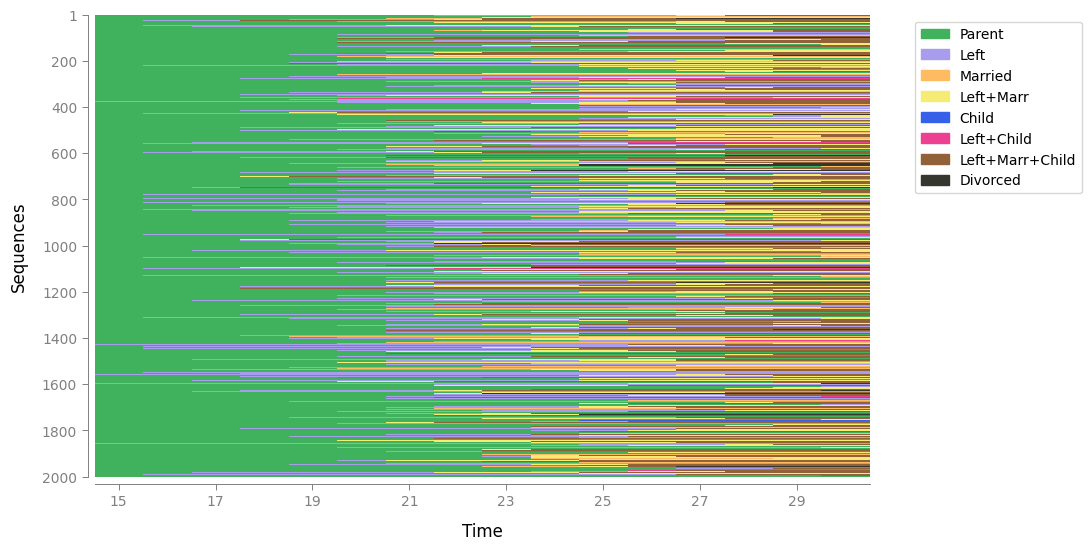

In [18]:
sequenzo.plot_sequence_index(
    biofam_seq,
    sort_by="unsorted"
)

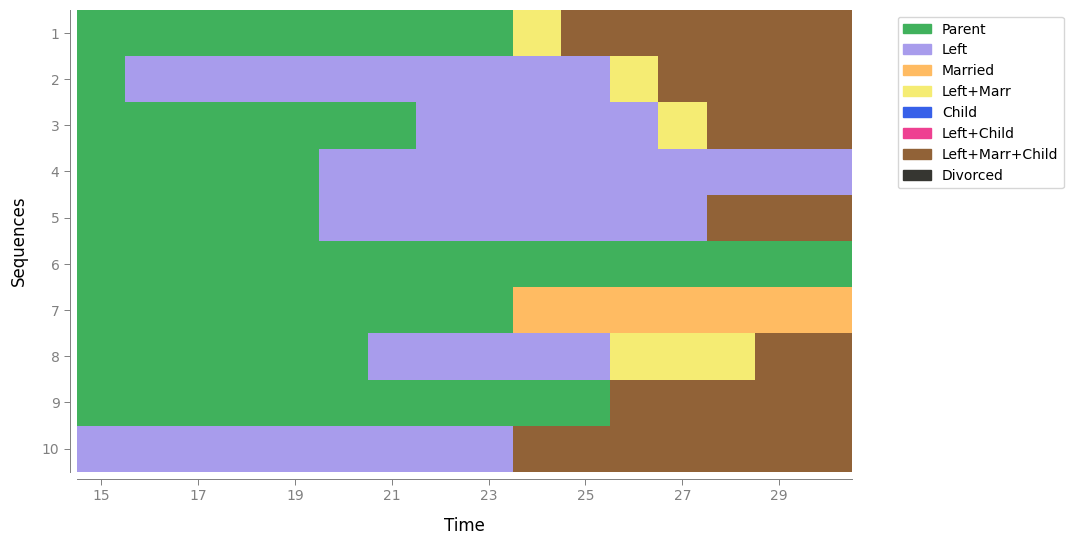

In [19]:
sequenzo.plot_sequence_index(
    biofam_seq,
    sort_by="unsorted",
    sequence_selection="first_n",
    n_sequences=10
)

### Fréqeunces des séquences

`sequenzo` propose uniquement de visualiser le graphe des fréquences cumulatives des séquences les plus fréquentes mais pas la table directement pour l'ensemble des séquences.

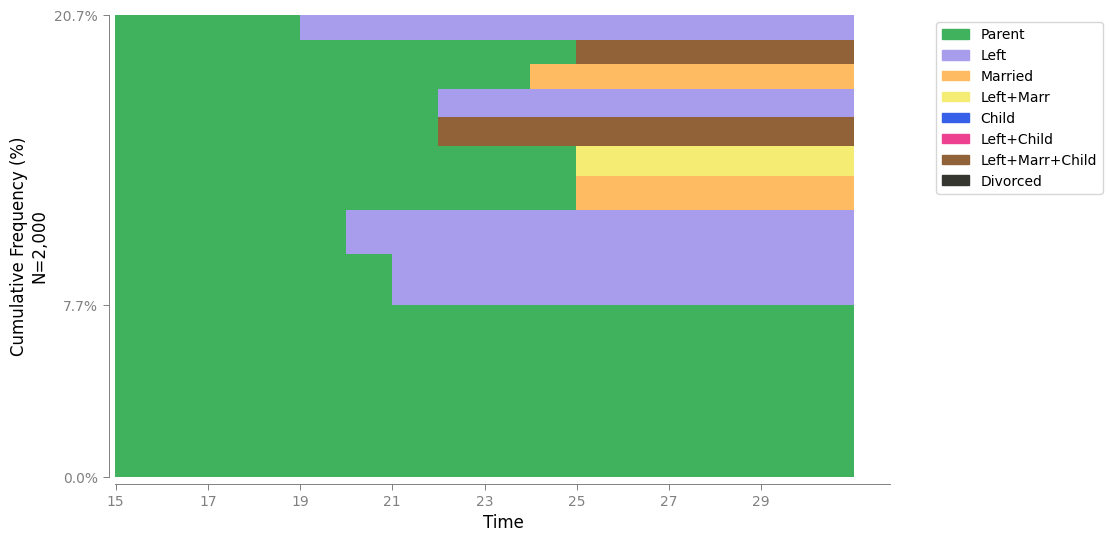

In [20]:
sequenzo.plot_most_frequent_sequences(
    biofam_seq,
    top_n=10,         # how many sequences to show
    save_as=None,     # e.g., "top_sequences.png"
    dpi=200
)

In [21]:
# Fréquences
sequences_tuples = [tuple(row) for row in arr]
from collections import Counter
counts = Counter(sequences_tuples)
df_freq = pd.DataFrame([
    {"sequence": list(seq), "frequency": freq/len(arr)}
    for seq, freq in counts.most_common()
])

print(df_freq.sort_values("frequency").tail(10))

                                            sequence  frequency
7   [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2]     0.0110
10  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 6, 6, 6, 6, 6]     0.0110
9   [0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]     0.0110
6   [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1]     0.0125
5   [0, 0, 0, 0, 0, 0, 0, 6, 6, 6, 6, 6, 6, 6, 6, 6]     0.0130
4   [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 3, 3, 3, 3, 3]     0.0135
3   [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2]     0.0150
2   [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]     0.0200
1   [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]     0.0225
0   [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]     0.0770


### Fréquences des états co-occurents

`sequenzo` ne propose pas de fonction permettant d'obtenir les fréquences des états co-occurents.

In [22]:
from collections import Counter

# For each individual, get the frozenset of unique states visited
state_sets = [frozenset(row) for row in arr]

counts = Counter(state_sets)

df_stocc = pd.DataFrame([
    {"states": sorted(seq), "frequency": freq/len(arr)}
    for seq, freq in counts.most_common()
])

print(df_stocc.sort_values("frequency").tail(10))

         states  frequency
9     [0, 3, 7]     0.0105
8     [0, 1, 6]     0.0585
7           [0]     0.0770
6        [0, 6]     0.0850
5     [0, 1, 3]     0.0890
4        [0, 3]     0.0930
3        [0, 2]     0.1025
2  [0, 1, 3, 6]     0.1295
1        [0, 1]     0.1350
0     [0, 3, 6]     0.1465


### Séquence représentative

`sequenzo` ne met pas à disposition de fonction permettant d'extraire la séquence représentative (la séquence composée de l'état le plus populaire à chaque point de temps) mais propose une visualisation.

In [23]:
from scipy import stats
modal_states = stats.mode(arr, axis=0).mode
print("-".join(str(s) for s in modal_states))

0-0-0-0-0-0-0-0-0-0-1-6-6-6-6-6


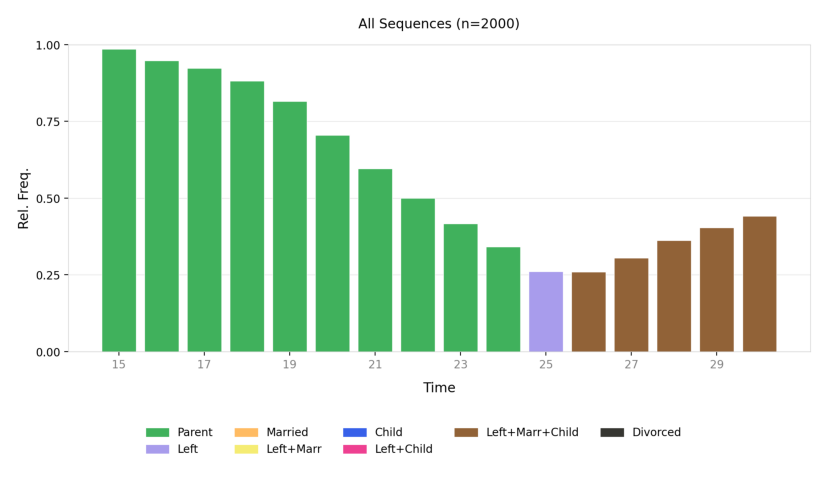

In [24]:
sequenzo.plot_modal_state(
    biofam_seq
)

### Temps moyen dans chaque état

De nouveau, `sequenzo` ne permet pas d'obtenir directement la table contenant le temps moyen passé dans chaque état mais propose une visualisation.

In [25]:
all_states = sorted(biofam[timepoints_columns].stack().unique())
mean_time = pd.DataFrame(
    {state: (arr == state).sum(axis=1) for state in all_states}
).mean()
print(mean_time)

0    8.0280
1    2.9440
2    0.7330
3    1.6220
4    0.0095
5    0.0835
6    2.4190
7    0.1610
dtype: float64


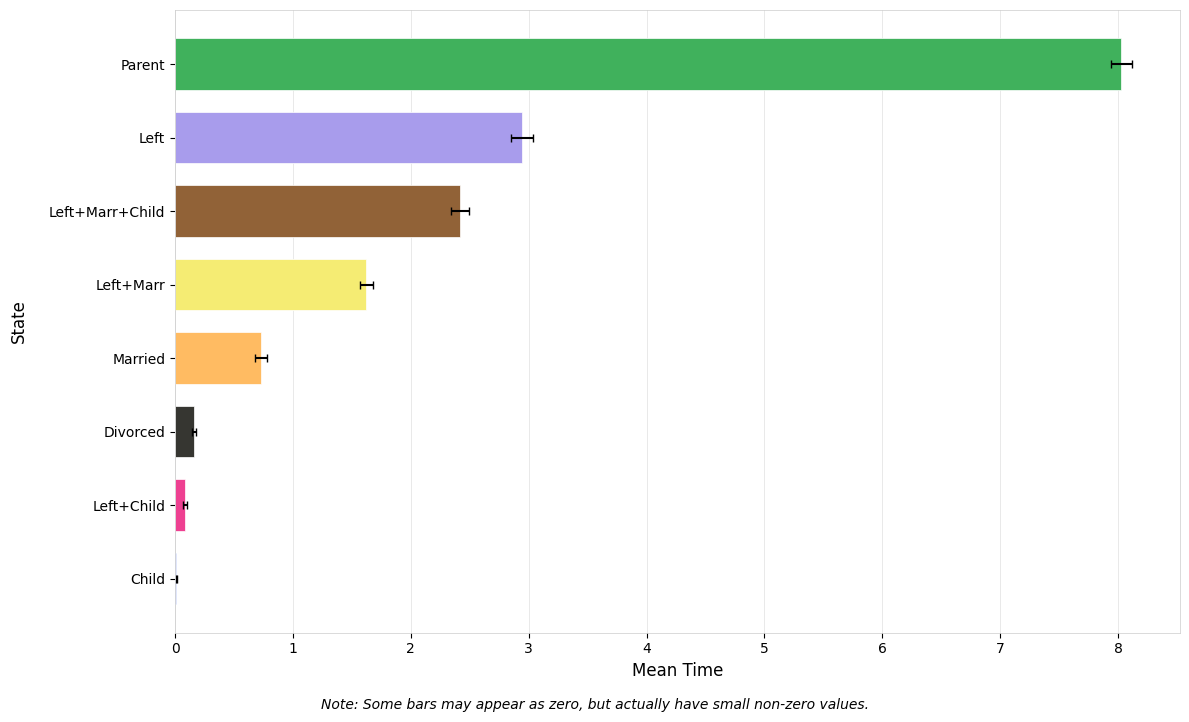

In [26]:
sequenzo.plot_mean_time(biofam_seq)

### Tableau des transitions

A nouveau, l'utilisateur n'a pas accès directement à la table de transitions entre les états mais `sequenzo` propose une visualisation.

In [27]:
from_states = arr[:, :-1].flatten()
to_states   = arr[:, 1:].flatten()

transition_counts = pd.crosstab(
    pd.Series(from_states, name="from"),
    pd.Series(to_states, name="to")
)

# Normalize by row to get probabilities
transition_probs = transition_counts.div(transition_counts.sum(axis=1), axis=0)

print(transition_probs.round(3))

to        0      1      2      3      4      5      6      7
from                                                        
0     0.886  0.055  0.015  0.032  0.000  0.001  0.011  0.000
1     0.000  0.890  0.000  0.083  0.000  0.004  0.023  0.000
2     0.000  0.000  0.969  0.010  0.000  0.000  0.011  0.010
3     0.000  0.000  0.000  0.787  0.000  0.000  0.199  0.014
4     0.000  0.000  0.125  0.000  0.812  0.062  0.000  0.000
5     0.000  0.000  0.000  0.000  0.000  0.882  0.118  0.000
6     0.000  0.000  0.000  0.000  0.000  0.000  0.994  0.006
7     0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.000


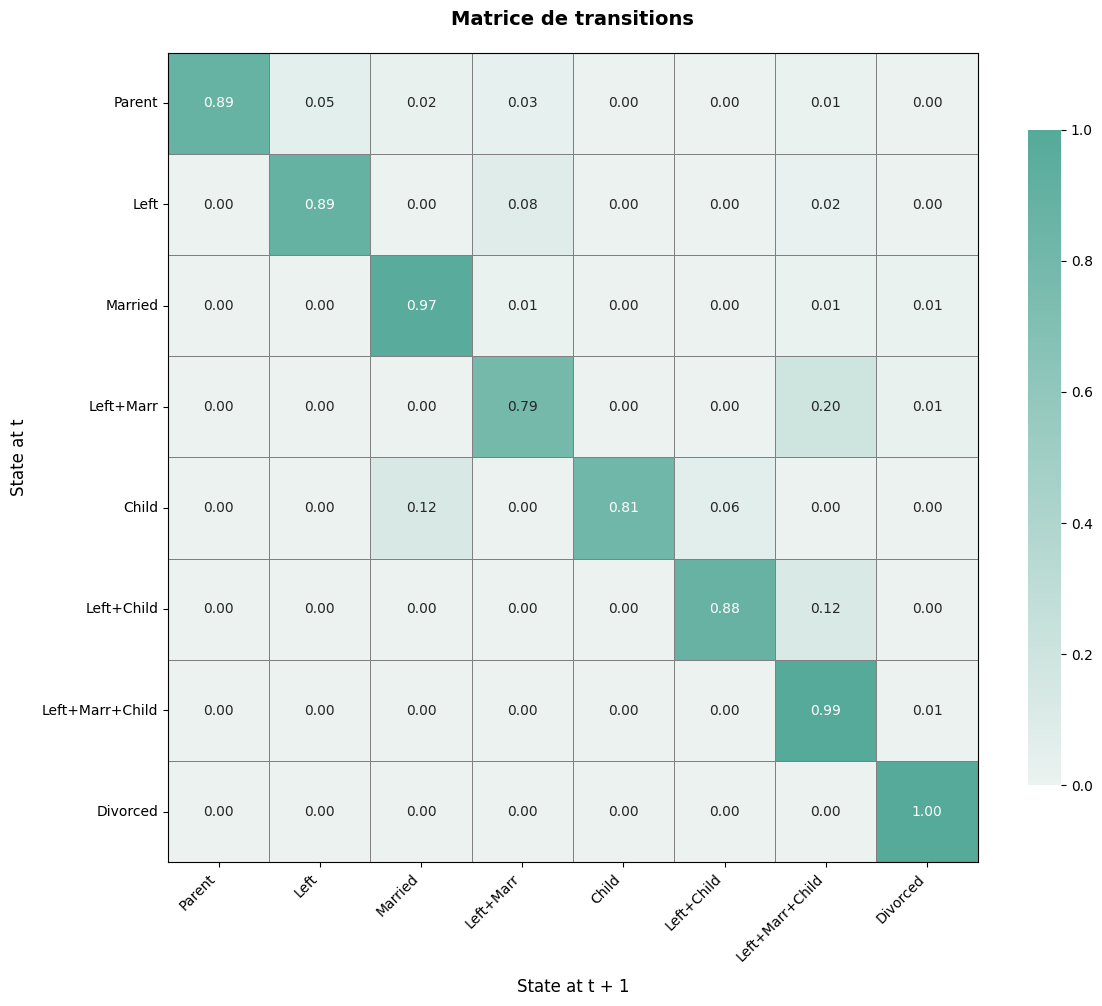

In [28]:
sequenzo.plot_transition_matrix(
    biofam_seq,
    weights="auto",        # sequence weights; "auto" uses seqdata.weights if available
    title="Matrice de transitions",
    fontsize=12 
)

### Distribution transversale

`sequenzo` ne permet pas d'accèder à la table contenant la distribution transversale de chaque état mais propose une visualisation.

In [29]:
# Pour chaque pas de temps, la proportion de chaque état
cross_dist = pd.DataFrame(
    {t: pd.Series(arr[:, i]).value_counts(normalize=True) for i, t in enumerate(timepoints_columns)}
).T.fillna(0).sort_index()

cross_dist.columns = [biofam_seq.state_to_label[i] for i in sorted(cross_dist.columns)]
print(cross_dist.round(3))

    Parent   Left  Married  Left+Marr  Child  Left+Child  Left+Marr+Child  \
15   0.986  0.014    0.000      0.000  0.000       0.000            0.000   
16   0.948  0.052    0.000      0.000  0.000       0.000            0.000   
17   0.924  0.075    0.000      0.000  0.000       0.000            0.000   
18   0.881  0.108    0.003      0.002  0.000       0.000            0.005   
19   0.816  0.152    0.007      0.013  0.000       0.002            0.011   
20   0.706  0.226    0.016      0.022  0.000       0.003            0.027   
21   0.596  0.280    0.028      0.046  0.000       0.004            0.047   
22   0.500  0.295    0.038      0.079  0.000       0.004            0.080   
23   0.416  0.294    0.050      0.113  0.001       0.006            0.118   
24   0.341  0.283    0.061      0.150  0.000       0.006            0.152   
25   0.254  0.261    0.073      0.186  0.001       0.006            0.207   
26   0.201  0.230    0.080      0.204  0.001       0.007            0.260   

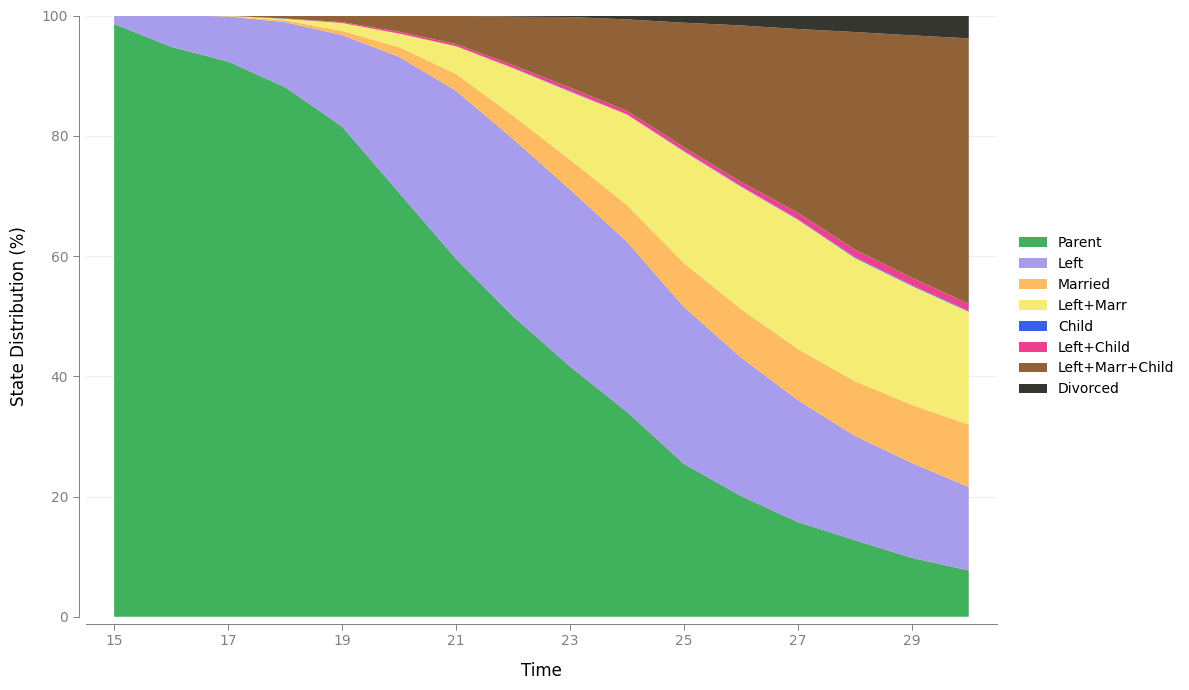

In [30]:
sequenzo.plot_state_distribution(biofam_seq)

### Entropie transversale

In [31]:
sequenzo.get_cross_sectional_entropy(biofam_seq) 


Cross-Sectional Entropy Summary
[>] Number of states: 8
[>] Number of time points: 16
[>] On average, the most common state accounts for 36.1% of cases
[>] Entropy is highest at time point 27
[>] Entropy is lowest at time point 15
[>] Average normalized entropy: 0.709 (range: 0 = fully concentrated, 1 = evenly distributed)



c:\Users\malnoeg\Documents\Stage_M2_SequenceAnalysis\venv-sequenzo\Lib\site-packages\sequenzo\sequence_characteristics_indicators\overall_cross_sectional_entropy.py:109: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  P = np.divide(freq_counts, N_valid, where=(N_valid>0))  # Frequencies


,time,state,freq,per_time_entropy_norm,N_valid,Effective States,rank,is_top
0,15,1,0.500000,0.351046,4000.0,2.075037,1,True
1,15,0,0.493000,0.351046,4000.0,2.075037,2,False
2,15,2,0.007000,0.351046,4000.0,2.075037,3,False
3,15,3,0.000000,0.351046,4000.0,2.075037,4,False
4,15,4,0.000000,0.351046,4000.0,2.075037,5,False
...,...,...,...,...,...,...,...,...
123,30,2,0.123598,0.891322,3924.0,6.381812,4,False
124,30,1,0.110092,0.891322,3924.0,6.381812,5,False
125,30,4,0.096585,0.891322,3924.0,6.381812,6,False
126,30,0,0.039246,0.891322,3924.0,6.381812,7,False



Cross-Sectional Entropy Summary
[>] Number of states: 8
[>] Number of time points: 16
[>] On average, the most common state accounts for 36.1% of cases
[>] Entropy is highest at time point 27
[>] Entropy is lowest at time point 15
[>] Average normalized entropy: 0.709 (range: 0 = fully concentrated, 1 = evenly distributed)



c:\Users\malnoeg\Documents\Stage_M2_SequenceAnalysis\venv-sequenzo\Lib\site-packages\sequenzo\sequence_characteristics_indicators\overall_cross_sectional_entropy.py:109: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  P = np.divide(freq_counts, N_valid, where=(N_valid>0))  # Frequencies


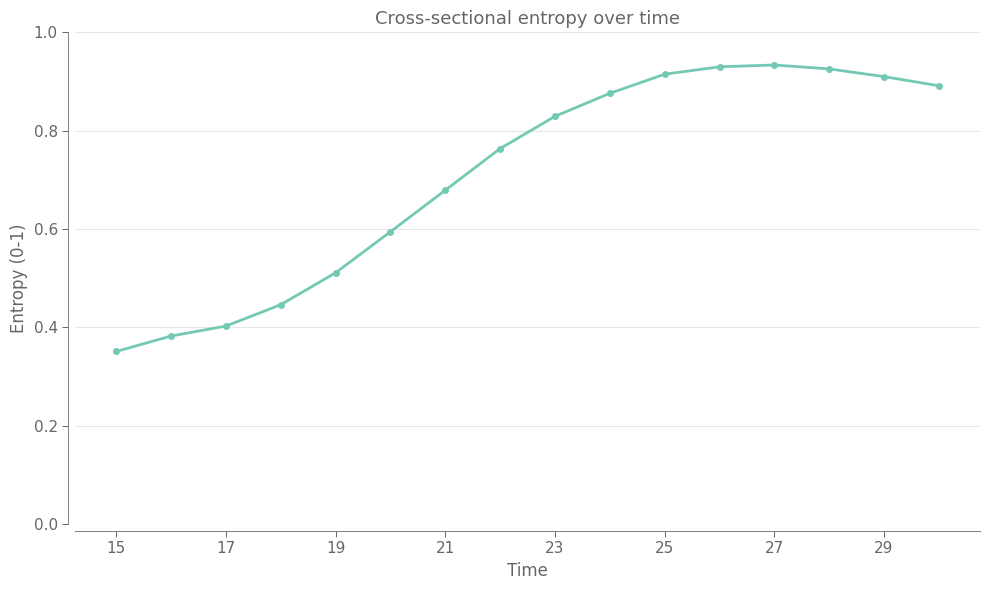

In [32]:
sequenzo.plot_cross_sectional_characteristics(biofam_seq) 

### Frequence relative

[>] Processing 2000 sequences with 8 unique states.
  - Creating 9x9 substitution-cost matrix using 2 as constant value
[>] generated an indel of type number

[>] Identified 537 unique sequences.
[>] Starting Optimal Matching(OM)...
[>] Computing all pairwise distances...
[>] Computed Successfully.


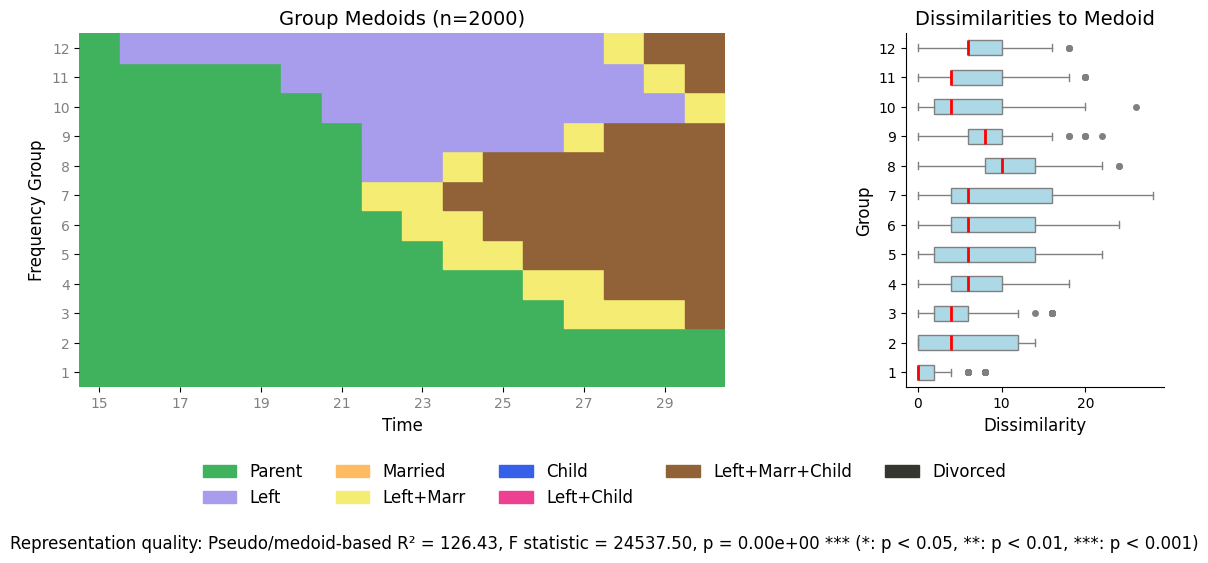

In [33]:
distance_matrix = sequenzo.get_distance_matrix(biofam_seq,method="OM",sm="constant")
sequenzo.plot_relative_frequency(
    biofam_seq,
    distance_matrix
)

### Single medoid

In [35]:
# Ne fonctionne pas mais est dans la documentation
#sequenzo.plot_single_medoid(
#    biofam_seq,
#    distance_matrix=distance_matrix,
#    show_legend=True
#)

### Descripteurs individuels

In [36]:
sequenzo.get_subsequences_all_sequences(biofam_seq)

,Subseq.
0,8
1,16
2,16
3,4
4,8
...,...
1995,8
1996,16
1997,2
1998,4


In [37]:
sequenzo.get_number_of_transitions(biofam_seq)

,ID,Transitions
0,0,2
1,1,3
2,2,3
3,3,1
4,4,2
...,...,...
1995,1995,2
1996,1996,3
1997,1997,0
1998,1998,1


In [38]:
sequenzo.get_spell_duration_variance(biofam_seq)

{'meand':         ID      meand
 0        0   5.333333
 1        1   4.000000
 2        2   4.000000
 3        3   8.000000
 4        4   5.333333
 ...    ...        ...
 1995  1995   5.333333
 1996  1996   4.000000
 1997  1997  16.000000
 1998  1998   8.000000
 1999  1999   8.000000
 
 [2000 rows x 2 columns],
 'result':         ID  var_spell_dur
 0        0      10.888889
 1        1      13.500000
 2        2       5.000000
 3        3       9.000000
 4        4       4.222222
 ...    ...            ...
 1995  1995       2.888889
 1996  1996       2.000000
 1997  1997       0.000000
 1998  1998      25.000000
 1999  1999       4.000000
 
 [2000 rows x 2 columns],
 'vmax':         ID    var_max
 0        0  37.555556
 1        1  27.000000
 2        2  27.000000
 3        3  49.000000
 4        4  37.555556
 ...    ...        ...
 1995  1995  37.555556
 1996  1996  27.000000
 1997  1997   0.000000
 1998  1998  49.000000
 1999  1999  49.000000
 
 [2000 rows x 2 columns]}

In [39]:
sequenzo.get_state_freq_and_entropy_per_seq(biofam_seq)

[>] Computing state distribution for 2000 sequences and 8 states ...


,ID,Parent,Left,Married,Left+Marr,Child,Left+Child,Left+Marr+Child,Divorced
0,0,9.0,0.0,0.0,1.0,0.0,0.0,6.0,0.0
1,1,1.0,10.0,0.0,1.0,0.0,0.0,4.0,0.0
2,2,7.0,5.0,0.0,1.0,0.0,0.0,3.0,0.0
3,3,5.0,11.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,5.0,8.0,0.0,0.0,0.0,0.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...
1995,1995,6.0,3.0,0.0,0.0,0.0,0.0,7.0,0.0
1996,1996,2.0,6.0,0.0,4.0,0.0,0.0,4.0,0.0
1997,1997,16.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1998,1998,3.0,0.0,13.0,0.0,0.0,0.0,0.0,0.0


In [40]:
sequenzo.get_within_sequence_entropy(biofam_seq)

,ID,Entropy
0,0,0.415852
1,1,0.474598
2,2,0.583000
3,3,0.298679
4,4,0.492406
...,...,...
1995,1995,0.501747
1996,1996,0.635213
1997,1997,0.000000
1998,1998,0.232071


In [41]:
sequenzo.get_complexity_index(biofam_seq)

,ID,Complexity Index
0,0,0.235472
1,1,0.308090
2,2,0.341467
3,3,0.141110
4,4,0.256231
...,...,...
1995,1995,0.258650
1996,1996,0.356430
1997,1997,0.000000
1998,1998,0.124384


In [42]:
sequenzo.get_turbulence(biofam_seq)

[!] One or more missing values were found after calculating the number of distinct subsequences. They have been replaced with a large number of 1e15 to ensure the calculation continues.


,ID,Turbulence
0,0,4.697325
1,1,4.949374
2,2,6.222392
3,3,4.321928
4,4,5.884203
...,...,...
1995,1995,6.309509
1996,1996,7.222392
1997,1997,1.000000
1998,1998,2.943416


In [44]:
# Ne fonctionne pas mais est dans la documentation
#sequenzo.get_positive_negative_indicators(biofam_seq,  pos_states=[0, 1, 2, 3, 4, 5, 6], neg_states=[7])
#sequenzo.get_integration_index(biofam_seq)
#sequenzo.get_badness_index(biofam_seq)
#sequenzo.get_degradation_index(biofam_seq, method="RANK", penalized="BOTH")
#sequenzo.get_precarity_index(biofam_seq, otto=0.2, a=1.0, b=1.2, method="TRATEDSS")
#sequenzo.get_insecurity_index(biofam_seq, method="RANK", pow=1.0, bound=False)

[!] One or more missing values were found after calculating the number of distinct subsequences. They have been replaced with a large number of 1e15 to ensure the calculation continues.


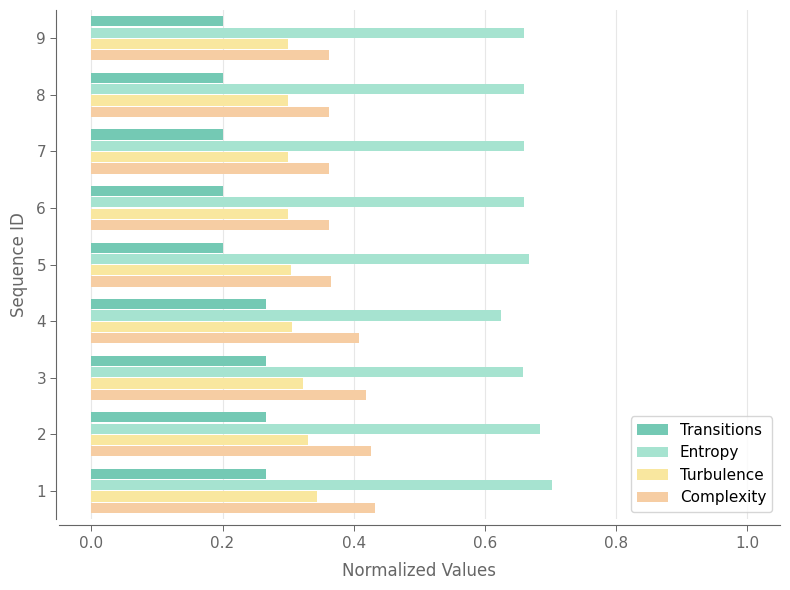

,ID,Transitions,Entropy,Turbulence,Complexity
0,722,0.266667,0.702820,0.343398,0.432919
1,37,0.266667,0.684140,0.330756,0.427127
2,1625,0.266667,0.658201,0.323178,0.418951
3,1954,0.266667,0.625000,0.306526,0.408248
4,379,0.200000,0.666667,0.304839,0.365148
5,1575,0.200000,0.659072,0.300220,0.363063
6,1563,0.200000,0.659072,0.300220,0.363063
7,671,0.200000,0.659072,0.300220,0.363063
8,1767,0.200000,0.659072,0.300220,0.363063


In [45]:
sequenzo.plot_longitudinal_characteristics(biofam_seq)

### Paramètres de visualisaion
`sequenzo` propose plusieurs niveau de personnalisation des visuels comme le changement de la palette de couleurs ou la sépération d'une visualisation selon un groupe.

[>] Creating grouped plots by 'sex' with 2 categories


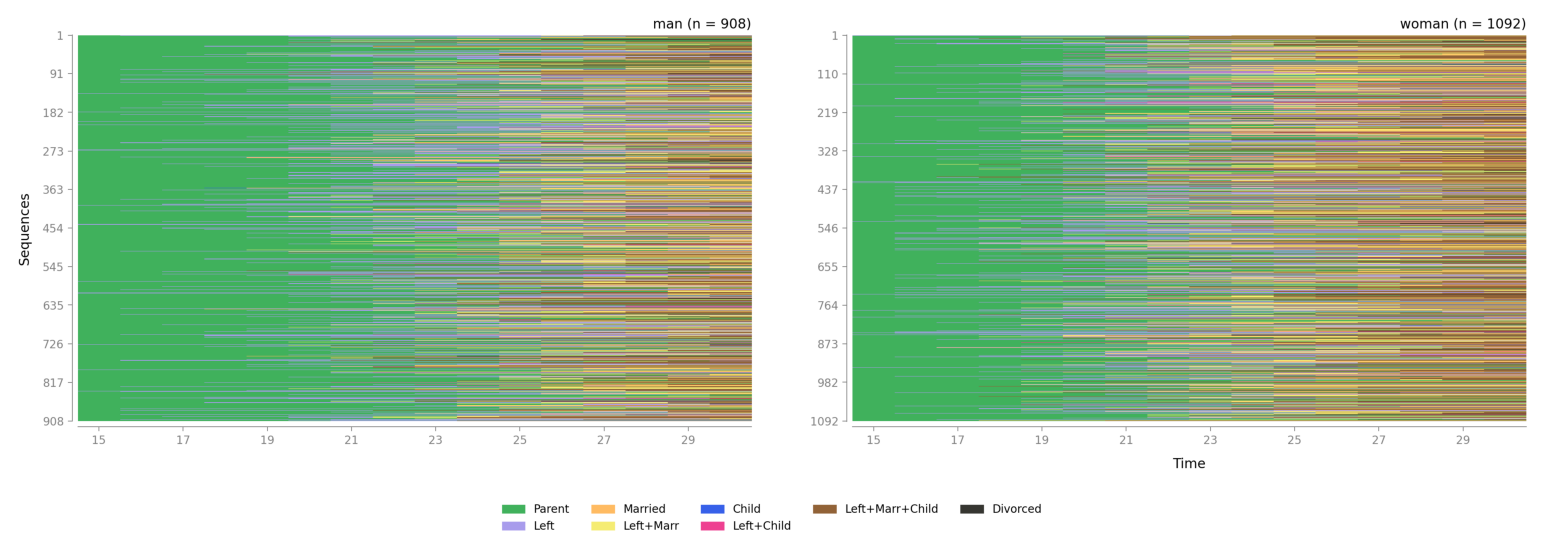

In [46]:
sequenzo.plot_sequence_index(
    biofam_seq,
    sort_by="unsorted",
    group_by_column="sex"
)

# 7. Obtention de typologies par l'analyse de séquences

L'une des application majeur de l'analyse de séquences est la construction de typologies : le regroupement des séquences partageant des propriétés similaires. L'identification de ces profils types permet ensuite de travailler avec des covariables afin d'expliquer la formation de ces différents groupes.

La construction de ces typologies se fait en deux étapes : l'évaluation des écarts entre chaque paire de séquence qui fournit une matrice de (di)similarités, puis l'application d'un algorithme de classification (clustering) sur cette matrice afin de former des groupes d'individus similaires (ou peu dissimilaires).

Pour chacune de ces étapes, le package `sequenzo` propose plusieurs possibilités que nous allons illustrer sur le jeu de données `biofam`.

## 7.1 Calcul matrice de distances (dissimilarités)
La librairie `sequenzo` propose de nombreuses métrique pour calculer la dissimilarité entre les séquences :

In [47]:
start_time = time.time()
distance_matrix = sequenzo.get_distance_matrix(biofam_seq, method="OM", sm="constant")
distance_matrix
time_taken = time.time() - start_time
print(str(time_taken)+" s")

[>] Processing 2000 sequences with 8 unique states.
  - Creating 9x9 substitution-cost matrix using 2 as constant value
[>] generated an indel of type number

[>] Identified 537 unique sequences.
[>] Starting Optimal Matching(OM)...
[>] Computing all pairwise distances...
[>] Computed Successfully.
0.11284732818603516 s


In [48]:
distance_matrix.index

Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999],
      dtype='int64', length=2000)

### 7.2 Clustering
Une fois la matrice de dissimilarité calculée, la seconde étape consiste à regrouper les trajectoires similaires au moyen d'un algorithme de clustering. `sequenzo` propose directement plusieurs algorithmes de clustering...

In [49]:
start_time = time.time()
cluster = sequenzo.Cluster(
    matrix=distance_matrix, 
    entity_ids=distance_matrix.index, 
    clustering_method="ward"
)  
cluster_results = sequenzo.ClusterResults(cluster)
members = cluster_results.get_cluster_memberships(num_clusters=2)     
time_taken = time.time() - start_time
print(str(time_taken)+" s")

26.185077905654907 s


c:\Users\malnoeg\Documents\Stage_M2_SequenceAnalysis\venv-sequenzo\Lib\site-packages\sequenzo\clustering\hierarchical_clustering.py:308: UserWarning: 
[!] Ward linkage method detected with potentially non-Euclidean distance matrix!
   Ward clustering (both Ward D and Ward D2) assumes Euclidean distances for theoretical validity.
   
   Ward method variants:
   - 'ward_d' (classic): Uses squared Euclidean distances ÷ 2
   - 'ward_d2': Uses squared Euclidean distances
   
   For sequence distances (OM, LCS, etc.), consider using:
   - method='average' (UPGMA)
   - method='complete' (complete linkage)
   - method='single' (single linkage)
   
   Note: 'centroid' and 'median' methods may also produce inversions
   (non-monotonic dendrograms) with non-Euclidean distances.
   
   This warning is shown only once per session.
  self._warn_from_flags(int(result["warning_flags"]), self.clustering_method)


In [50]:
members

,Entity ID,Cluster
0,0,1
1,1,2
2,2,2
3,3,2
4,4,2
...,...,...
1995,1995,1
1996,1996,2
1997,1997,1
1998,1998,1


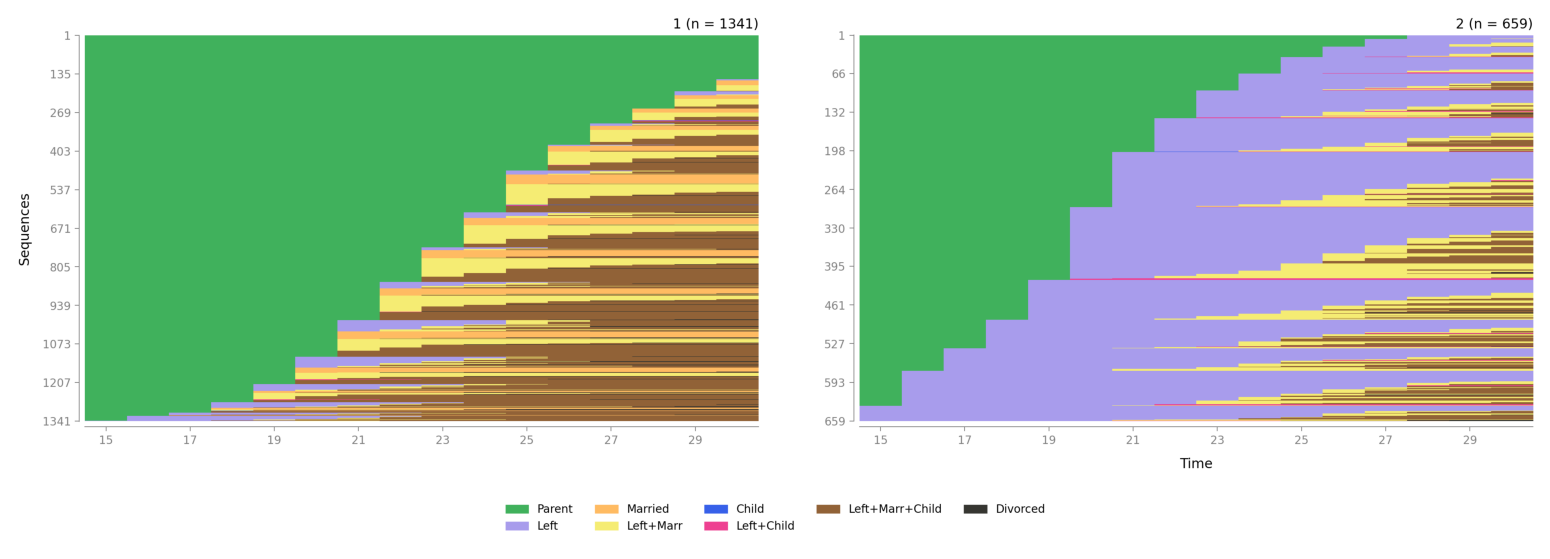

In [51]:
sequenzo.plot_sequence_index(biofam_seq, 
                    group_dataframe=members, 
                    group_column_name="Cluster")

### 7.3 Cas du multichannel
L'analyse de séquences ne se limite pas qu'au cas unidimensionnel comme illustré précedemment et peut-être également intéressantes dans un contexte multidiomensionnel pour plusieurs individus reliés entre eux ou plusieurs aspects d'un même individu.

Le processus analytique dans le cadre multidimensionnel reste globalement le même : il s'agit toujours de définir des séquences à partir d'un certain alphabet d'états, de choisir le coût du passage d'un état à un autre, de calculer la dissimilarité entre les trajectoires et d'appliquer une algorithme de clustering. L'enjeu devient alors de choisir le moment auquel considérer l'aspect multidimensionnel. Quatre approches se distingues : extension de l'alphabet (EA, *Extended Alphabet*), association des matrices de coût (CAT, *Cost Additive Trick*), association des matrices de dissimilarité (DAT, *Distance Additive Trick*) et combinaison des clusters (CombT, *Combining Trajectories*) qui sont toutes implémentables en Python avec `sequenzo`.

Nous allons illustrer ces possibilités avec le jeu de données `extract_shp`.

### Extended Alphabet

In [52]:
start_time = time.time()
# Lien vers les fichiers CSV préparés précédemment
csv_paths = [
    "C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_region.csv",
    "C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_community.csv",
    "C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_type_logement.csv",
    "C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_nbpers.csv",
    "C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_condlieuvie.csv",
    "C:/Users/malnoeg/Documents/Stage_M2_SequenceAnalysis/Protocole/Code/data_SHP_sts_situatuionfinance.csv"
]
time_cols_shp = ["1999","2000","2001","2002","2003","2004","2005","2006","2007","2008","2009","2010","2011","2012","2013","2014","2015","2016","2017","2018"]
# Sequences pour EA (IDCD)
sequence_data = sequenzo.create_idcd_sequence_from_csvs(
    id_col="idhous",
    csv_paths=csv_paths,
    time_cols=time_cols_shp
)

distance_matrix = sequenzo.dissimilarity_measures.get_distance_matrix(
    seqdata=sequence_data,
    method="OM",
    sm="CONSTANT",
    indel="auto"
)

cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=sequence_data.ids)
labels = cluster_result.get_cluster_labels(num_clusters=4)

time_taken = time.time() - start_time
print(f"Temps d'exécution : {time_taken:.2f} s")


[IDCD] Observed Combined States Frequency Table:
             State              Label  Frequency  Proportion (%)
     4+2+2+2+2+7-8      4+2+2+2+2+7-8        197            0.95
    4+2+2+2+2+9-10     4+2+2+2+2+9-10        181            0.88
     4+1+1+2+2+7-8      4+1+1+2+2+7-8        147            0.71
     4+1+1+1+2+7-8      4+1+1+1+2+7-8        135            0.65
     4+2+1+1+2+7-8      4+2+1+1+2+7-8        134            0.65
    2+2+2+2+2+9-10     2+2+2+2+2+9-10        120            0.58
     1+1+1+1+2+7-8      1+1+1+1+2+7-8        117            0.57
     2+1+1+2+2+7-8      2+1+1+2+2+7-8        103            0.50
     3+2+2+2+2+7-8      3+2+2+2+2+7-8        100            0.48
     2+4+2+2+2+7-8      2+4+2+2+2+7-8         99            0.48
     4+2+1+2+2+7-8      4+2+1+2+2+7-8         99            0.48
     2+2+1+1+2+7-8      2+2+1+1+2+7-8         98            0.47
     2+2+2+2+2+7-8      2+2+2+2+2+7-8         97            0.47
     1+1+1+2+2+7-8      1+1+1+2+2+7-8   

### Cost Additive Trick

In [58]:
extract_shp_sts_region = extract_shp_sts_region.astype(str)
extract_shp_sts_community = extract_shp_sts_community.astype(str)
extract_shp_sts_type_logement = extract_shp_sts_type_logement.astype(str)
extract_shp_sts_nbpers = extract_shp_sts_nbpers.astype(str)
extract_shp_sts_condlieuvie = extract_shp_sts_condlieuvie.astype(str)
extract_shp_sts_situatuionfinance = extract_shp_sts_situatuionfinance.astype(str)

In [55]:
start_time = time.time()
# Region (Conversion des états en STR)
shp_region_seq = sequenzo.SequenceData(
    data=extract_shp_sts_region,
    time=["region_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3,4,5,6,7]], # Force str
    id_col="idhous"
)
# Community
shp_community_seq = sequenzo.SequenceData(
    data=extract_shp_sts_community,
    time=["com2__"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3,4,5,6,7,8,9]], # Force str
    id_col="idhous"
)
# Type logement
shp_type_logement_seq = sequenzo.SequenceData(
    data=extract_shp_sts_type_logement,
    time=["hh29_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3]], # Force str
    id_col="idhous"
)
# Condition de lieu de vie
shp_condlieuvie_seq = sequenzo.SequenceData(
    data=extract_shp_sts_condlieuvie,
    time=["hh14_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3]], # Force str
    id_col="idhous"
)
# Nb personnes dans le foyer
shp_nbpers_seq = sequenzo.SequenceData(
    data=extract_shp_sts_nbpers,
    time=["nbpers_"+str(year) for year in range(1999,2019)],
    states=["1","2","3","4","5plus"],
    id_col="idhous"
)
# Situation financière
shp_situation_finance_seq = sequenzo.SequenceData(
    data=extract_shp_sts_situatuionfinance,
    time=["hi30_"+str(year) for year in range(1999,2019)],
    states=["0-1","2-3","4-6","7-8","9-10"],
    id_col="idhous"
) 
distance_matrix = sequenzo.compute_cat_distance_matrix(
    [shp_region_seq, shp_community_seq, shp_type_logement_seq, shp_nbpers_seq, shp_condlieuvie_seq, shp_situation_finance_seq],
    method="OM",
    sm=["CONSTANT","CONSTANT","CONSTANT","CONSTANT","CONSTANT","CONSTANT"],
    indel=[1,1,1,1,1,1],
    what="diss"
)
cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=shp_region_seq.ids)
labels = cluster_result.get_cluster_labels(num_clusters=4)
time_taken = time.time() - start_time
print(str(time_taken)+" s")


[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3', '4', '5', '6', '7']
[>] Labels: ['1', '2', '3', '4', '5', '6', '7']
[>] Weights: Not provided

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3', '4', '5', '6', '7', '8', '9']
[>] Labels: ['1', '2', '3', '4', '5', '6', '7', '8', '9']
[>] Weights: Not provided

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3']
[>] Labels: ['1', '2', '3']
[>] Weights: Not provided

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', 

### Distance Additive Trick

In [56]:
start_time = time.time()
# Region (Conversion des états en STR)
shp_region_seq = sequenzo.SequenceData(
    data=extract_shp_sts_region,
    time=["region_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3,4,5,6,7]], # Force str
    id_col="idhous"
)
# Community
shp_community_seq = sequenzo.SequenceData(
    data=extract_shp_sts_community,
    time=["com2__"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3,4,5,6,7,8,9]], # Force str
    id_col="idhous"
)
# Type logement
shp_type_logement_seq = sequenzo.SequenceData(
    data=extract_shp_sts_type_logement,
    time=["hh29_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3]], # Force str
    id_col="idhous"
)
# Condition de lieu de vie
shp_condlieuvie_seq = sequenzo.SequenceData(
    data=extract_shp_sts_condlieuvie,
    time=["hh14_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3]], # Force str
    id_col="idhous"
)
# Nb personnes dans le foyer
shp_nbpers_seq = sequenzo.SequenceData(
    data=extract_shp_sts_nbpers,
    time=["nbpers_"+str(year) for year in range(1999,2019)],
    states=["1","2","3","4","5plus"],
    id_col="idhous"
)
# Situation financière
shp_situation_finance_seq = sequenzo.SequenceData(
    data=extract_shp_sts_situatuionfinance,
    time=["hi30_"+str(year) for year in range(1999,2019)],
    states=["0-1","2-3","4-6","7-8","9-10"],
    id_col="idhous"
) 
distance_matrix = sequenzo.compute_dat_distance_matrix(
    sequence_objects=[shp_region_seq, shp_community_seq, shp_type_logement_seq, shp_nbpers_seq, shp_condlieuvie_seq, shp_situation_finance_seq], 
    method_params=[{"method": "OM", "sm": "CONSTANT", "indel": 1},{"method": "OM", "sm": "CONSTANT", "indel": 1},{"method": "OM", "sm": "CONSTANT", "indel": 1},
                   {"method": "OM", "sm": "CONSTANT", "indel": 1},{"method": "OM", "sm": "CONSTANT", "indel": 1},{"method": "OM", "sm": "CONSTANT", "indel": 1}]
                   )
cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=shp_region_seq.ids)
labels = cluster_result.get_cluster_labels(num_clusters=4)
time_taken = time.time() - start_time
print(str(time_taken)+" s")



[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3', '4', '5', '6', '7']
[>] Labels: ['1', '2', '3', '4', '5', '6', '7']
[>] Weights: Not provided

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3', '4', '5', '6', '7', '8', '9']
[>] Labels: ['1', '2', '3', '4', '5', '6', '7', '8', '9']
[>] Weights: Not provided

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3']
[>] Labels: ['1', '2', '3']
[>] Weights: Not provided

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', 

### Combining Trajectories

In [60]:
start_time = time.time()
# Region (Conversion des états en STR)
shp_region_seq = sequenzo.SequenceData(
    data=extract_shp_sts_region,
    time=["region_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3,4,5,6,7]], # Force str
    id_col="idhous"
)
# Community
shp_community_seq = sequenzo.SequenceData(
    data=extract_shp_sts_community,
    time=["com2__"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3,4,5,6,7,8,9]], # Force str
    id_col="idhous"
)
# Type logement
shp_type_logement_seq = sequenzo.SequenceData(
    data=extract_shp_sts_type_logement,
    time=["hh29_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3]], # Force str
    id_col="idhous"
)
# Condition de lieu de vie
shp_condlieuvie_seq = sequenzo.SequenceData(
    data=extract_shp_sts_condlieuvie,
    time=["hh14_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3]], # Force str
    id_col="idhous"
)
# Nb personnes dans le foyer
shp_nbpers_seq = sequenzo.SequenceData(
    data=extract_shp_sts_nbpers,
    time=["nbpers_"+str(year) for year in range(1999,2019)],
    states=["1","2","3","4","5plus"],
    id_col="idhous"
)
# Situation financière
shp_situation_finance_seq = sequenzo.SequenceData(
    data=extract_shp_sts_situatuionfinance,
    time=["hi30_"+str(year) for year in range(1999,2019)],
    states=["0-1","2-3","4-6","7-8","9-10"],
    id_col="idhous"
) 
diss_matrices, membership_df = sequenzo.get_interactive_combined_typology(
    domains=[shp_region_seq, shp_community_seq, shp_type_logement_seq, shp_nbpers_seq, shp_condlieuvie_seq, shp_situation_finance_seq], 
    method_params=[{"method": "OM", "sm": "CONSTANT", "indel": 1},{"method": "OM", "sm": "CONSTANT", "indel": 1},{"method": "OM", "sm": "CONSTANT", "indel": 1},
                   {"method": "OM", "sm": "CONSTANT", "indel": 1},{"method": "OM", "sm": "CONSTANT", "indel": 1},{"method": "OM", "sm": "CONSTANT", "indel": 1}]
)
cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=shp_region_seq.ids)
labels = cluster_result.get_cluster_labels(num_clusters=4)
time_taken = time.time() - start_time
print(str(time_taken)+" s")



[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3', '4', '5', '6', '7']
[>] Labels: ['1', '2', '3', '4', '5', '6', '7']
[>] Weights: Not provided

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3', '4', '5', '6', '7', '8', '9']
[>] Labels: ['1', '2', '3', '4', '5', '6', '7', '8', '9']
[>] Weights: Not provided

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3']
[>] Labels: ['1', '2', '3']
[>] Weights: Not provided

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', 

In [57]:
start_time = time.time()
# Region (Conversion des états en STR)
shp_region_seq = sequenzo.SequenceData(
    data=extract_shp_sts_region,
    time=["region_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3,4,5,6,7]], # Force str
    id_col="idhous"
)
distance_matrix = sequenzo.get_distance_matrix(shp_region_seq, method="OM", sm="CONSTANT", indel=1)
cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=shp_region_seq.ids)
labels_region = cluster_result.get_cluster_labels(num_clusters=4)
# Community
shp_community_seq = sequenzo.SequenceData(
    data=extract_shp_sts_community,
    time=["com2__"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3,4,5,6,7,8,9]], # Force str
    id_col="idhous"
)
distance_matrix = sequenzo.get_distance_matrix(shp_community_seq, method="OM", sm="CONSTANT", indel=1)
cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=shp_community_seq.ids)
labels_community = cluster_result.get_cluster_labels(num_clusters=4)
# Type logement
shp_type_logement_seq = sequenzo.SequenceData(
    data=extract_shp_sts_type_logement,
    time=["hh29_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3]], # Force str
    id_col="idhous"
)
distance_matrix = sequenzo.get_distance_matrix(shp_type_logement_seq, method="OM", sm="CONSTANT", indel=1)
cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=shp_type_logement_seq.ids)
labels_type_logement = cluster_result.get_cluster_labels(num_clusters=4)
# Condition de lieu de vie
shp_condlieuvie_seq = sequenzo.SequenceData(
    data=extract_shp_sts_condlieuvie,
    time=["hh14_"+str(year) for year in range(1999,2019)],
    states=[str(s) for s in [1,2,3]], # Force str
    id_col="idhous"
)
distance_matrix = sequenzo.get_distance_matrix(shp_condlieuvie_seq, method="OM", sm="CONSTANT", indel=1)
cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=shp_condlieuvie_seq.ids)
labels_condlieuvie = cluster_result.get_cluster_labels(num_clusters=4)
# Nb personnes dans le foyer
shp_nbpers_seq = sequenzo.SequenceData(
    data=extract_shp_sts_nbpers,
    time=["nbpers_"+str(year) for year in range(1999,2019)],
    states=["1","2","3","4","5plus"],
    id_col="idhous"
)
distance_matrix = sequenzo.get_distance_matrix(shp_nbpers_seq, method="OM", sm="CONSTANT", indel=1)
cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=shp_nbpers_seq.ids)
labels_nbpers = cluster_result.get_cluster_labels(num_clusters=4)
# Situation financière
shp_situation_finance_seq = sequenzo.SequenceData(
    data=extract_shp_sts_situatuionfinance,
    time=["hi30_"+str(year) for year in range(1999,2019)],
    states=["0-1","2-3","4-6","7-8","9-10"],
    id_col="idhous"
) 
distance_matrix = sequenzo.get_distance_matrix(shp_situation_finance_seq, method="OM", sm="CONSTANT", indel=1)
cluster_result = sequenzo.clustering.hierarchical_clustering.Cluster(matrix=distance_matrix, entity_ids=shp_situation_finance_seq.ids)
labels_finance = cluster_result.get_cluster_labels(num_clusters=4)
# Combinaison des labels individuels pour chaque domaine
combined_labels = labels_region.astype(str) + "_" + labels_community.astype(str) + "_" + labels_type_logement.astype(str) + "_" + labels_condlieuvie.astype(str) + "_" + labels_nbpers.astype(str) + "_" + labels_finance.astype(str)
time_taken = time.time() - start_time
print(str(time_taken)+" s")


[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3', '4', '5', '6', '7']
[>] Labels: ['1', '2', '3', '4', '5', '6', '7']
[>] Weights: Not provided
[>] Processing 1032 sequences with 7 unique states.
  - Creating 8x8 substitution-cost matrix using 2 as constant value
[>] Identified 64 unique sequences.
[>] Starting Optimal Matching(OM)...
[>] Computing all pairwise distances...
[>] Computed Successfully.

[>] SequenceData initialized successfully! Here's a summary:
[>] Number of sequences: 1032
[>] Number of time points: 20
[>] Min/Max sequence length: 20 / 20
[>] States: ['1', '2', '3', '4', '5', '6', '7', '8', '9']
[>] Labels: ['1', '2', '3', '4', '5', '6', '7', '8', '9']
[>] Weights: Not provided
[>] Processing 1032 sequences with 9 unique states.
  - Creating 10x10 substitution-cost matrix using 2 as constant value
[>] Identified 245 unique sequences.